In [91]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import statsmodels.api as sm
import math

from scipy.stats import pearsonr
from sklearn.linear_model import Ridge
from sklearn.model_selection import TimeSeriesSplit, GridSearchCV


In [92]:
df = pd.read_csv("data_reg.csv")
print(df.head())

# If Date is in dd-mm-YYYY format, parse it like this:
df["Date"] = pd.to_datetime(df["Date"], dayfirst=True, errors="coerce")

# Make sure rows are in time order before using lag/shift
df = df.sort_values("Date").reset_index(drop=True)

         Date   Bund    BTP   FOAT  Bonos  DFR  ON-GcPooling  ON-ExtGcPooling  \
0  02-01-2018  0.467  2.095  0.823  1.614 -0.4        -0.439           -0.423   
1  03-01-2018  0.442  2.067  0.797  1.598 -0.4        -0.436           -0.418   
2  04-01-2018  0.434  2.014  0.786  1.543 -0.4        -0.443           -0.414   
3  05-01-2018  0.439  2.006  0.797  1.522 -0.4        -0.445           -0.402   
4  08-01-2018  0.431  1.984  0.788  1.482 -0.4        -0.449           -0.421   

   TN-GcPooling  TN-ExtGcPooling  ...  ON-GcPoolingVol  ON-ExtGcPoolingVol  \
0        -0.447           -0.450  ...           1770.0              3712.0   
1        -0.446           -0.440  ...           1534.0              2822.0   
2        -0.446           -0.435  ...           1909.0              2215.0   
3        -0.440           -0.388  ...           2179.0              4073.0   
4        -0.452           -0.411  ...           2050.0              3525.0   

   TN-GcPoolingVol  TN-ExtGcPoolingVol  SN-G

In [93]:
df["ECB_deferred_rate_new"] = (
    df["ON-GcPooling"] * df["ON-GcPoolingVol"]
    + df["TN-GcPooling"].shift(1) * df["TN-GcPoolingVol"].shift(1)
    + df["SN-GcPooling"].shift(2) * df["SN-GcPoolingVol"].shift(2)
) / (
    df["ON-GcPoolingVol"]
    + df["TN-GcPoolingVol"].shift(1)
    + df["SN-GcPoolingVol"].shift(2)
)

df["ECB_deferred_vol_new"] = (
    df["ON-GcPoolingVol"]
    + df["TN-GcPoolingVol"].shift(1)
    + df["SN-GcPoolingVol"].shift(2)
)

df["EXT_deferred_rate_new"] = (
    df["ON-ExtGcPooling"] * df["ON-ExtGcPoolingVol"]
    + df["TN-ExtGcPooling"].shift(1) * df["TN-ExtGcPoolingVol"].shift(1)
    + df["SN-ExtGcPooling"].shift(2) * df["SN-ExtGcPoolingVol"].shift(2)
) / (
    df["ON-ExtGcPoolingVol"]
    + df["TN-ExtGcPoolingVol"].shift(1)
    + df["SN-ExtGcPoolingVol"].shift(2)
)

df["EXT_deferred_vol_new"] = (
    df["ON-ExtGcPoolingVol"]
    + df["TN-ExtGcPoolingVol"].shift(1)
    + df["SN-ExtGcPoolingVol"].shift(2)
)

# Spread
df["DeferredRateSpread"] = df["EXT_deferred_rate_new"] - df["ECB_deferred_rate_new"]

# BTP-Bund spread (this part you intended as subtraction)
df["BTP_Bund_Spread"] = df["BTP"] - df["Bund"]

df["ExcessLiquidityLn"] = np.log(df["ExcessLiquidity"])

#Volume Spread
df["Volume_Spread"] = df["ECB_deferred_vol_new"] - df["EXT_deferred_vol_new"]
df["Liquidity_ratio"] = np.log(df["ECB_deferred_vol_new"]/ df["EXT_deferred_vol_new"])

df.head()

,Date,Bund,BTP,FOAT,Bonos,DFR,ON-GcPooling,ON-ExtGcPooling,TN-GcPooling,TN-ExtGcPooling,...,CISS_MM,ECB_deferred_rate_new,ECB_deferred_vol_new,EXT_deferred_rate_new,EXT_deferred_vol_new,DeferredRateSpread,BTP_Bund_Spread,ExcessLiquidityLn,Volume_Spread,Liquidity_ratio
0,2018-01-02,0.467,2.095,0.823,1.614,-0.4,-0.439,-0.423,-0.447,-0.450,...,0.0152,NaN,NaN,NaN,NaN,NaN,1.628,14.397679,NaN,NaN
1,2018-01-03,0.442,2.067,0.797,1.598,-0.4,-0.436,-0.418,-0.446,-0.440,...,0.0140,NaN,NaN,NaN,NaN,NaN,1.625,14.416495,NaN,NaN
2,2018-01-04,0.434,2.014,0.786,1.543,-0.4,-0.443,-0.414,-0.446,-0.435,...,0.0129,-0.443661,2449.0,-0.420993,3030.0,0.022668,1.580,14.425921,-581.0,-0.212883
3,2018-01-05,0.439,2.006,0.797,1.522,-0.4,-0.445,-0.402,-0.440,-0.388,...,0.0103,-0.445941,3029.0,-0.403210,4228.0,0.042731,1.567,14.424278,-1199.0,-0.333497
4,2018-01-08,0.431,1.984,0.788,1.482,-0.4,-0.449,-0.421,-0.452,-0.411,...,0.0122,-0.448701,2810.0,-0.411740,4900.0,0.036961,1.553,14.429584,-2090.0,-0.556051


In [94]:
#Conver to basis points
rate_cols = [
    "Bund", "BTP", "FOAT", "Bonos",
    "ON-GcPooling", "ON-ExtGcPooling",
    "TN-GcPooling", "TN-ExtGcPooling",
    "SN-GcPooling", "SN-ExtGcPooling",
    "DeferredRate",
    "ECB_deferred_rate_new", "EXT_deferred_rate_new",
    "DeferredRateSpread", "BTP_Bund_Spread","DFR", "CISS_MM"
]

df[rate_cols] = df[rate_cols] * 100

In [95]:
df["Date"] = pd.to_datetime(df["Date"], dayfirst=True, errors="coerce")
df = df.sort_values("Date").copy()
df=df.dropna()
df.columns
df.head()

,Date,Bund,BTP,FOAT,Bonos,DFR,ON-GcPooling,ON-ExtGcPooling,TN-GcPooling,TN-ExtGcPooling,...,CISS_MM,ECB_deferred_rate_new,ECB_deferred_vol_new,EXT_deferred_rate_new,EXT_deferred_vol_new,DeferredRateSpread,BTP_Bund_Spread,ExcessLiquidityLn,Volume_Spread,Liquidity_ratio
2,2018-01-04,43.4,201.4,78.6,154.3,-40.0,-44.3,-41.4,-44.6,-43.5,...,1.29,-44.366149,2449.0,-42.099340,3030.0,2.266810,158.0,14.425921,-581.0,-0.212883
3,2018-01-05,43.9,200.6,79.7,152.2,-40.0,-44.5,-40.2,-44.0,-38.8,...,1.03,-44.594090,3029.0,-40.320979,4228.0,4.273111,156.7,14.424278,-1199.0,-0.333497
4,2018-01-08,43.1,198.4,78.8,148.2,-40.0,-44.9,-42.1,-45.2,-41.1,...,1.22,-44.870107,2810.0,-41.173980,4900.0,3.696127,155.3,14.429584,-2090.0,-0.556051
5,2018-01-09,46.6,203.5,81.8,151.5,-40.0,-45.3,-41.3,-45.7,-41.3,...,1.15,-45.231011,2957.0,-41.268262,3781.0,3.962749,156.9,14.436468,-824.0,-0.245813
6,2018-01-10,54.3,203.8,81.3,155.1,-40.0,-44.9,-40.4,-44.7,-40.1,...,1.26,-45.088442,7164.0,-40.534013,5104.0,4.554430,149.5,14.438991,2060.0,0.339044


In [96]:
df2 = df[[
    "Date",
    "ExcessLiquidity",
    "ExcessLiquidityLn",
    "BTP_Bund_Spread",
    "DeferredRateSpread",
    "ECB_deferred_vol_new",
    "EXT_deferred_vol_new",
    "Liquidity_ratio",
    "CISS",
    "DFR",
    "ECB_deferred_rate_new", "EXT_deferred_rate_new", "DeferredVol", "DeferredRate","CISS_MM"
    #"Stress_State"
]].dropna().copy()


# 1. Define the outlier boundaries (1st and 99th percentiles)
lower_cutoff = df2['DeferredRateSpread'].quantile(0.05)
upper_cutoff = df2['DeferredRateSpread'].quantile(0.95)

# 2. Create the cleaned dataframe
# We use .copy() to ensure we aren't working on a slice of the original df
df3 = df2[(df2['DeferredRateSpread'] > lower_cutoff) & 
               (df2['DeferredRateSpread'] < upper_cutoff)].copy()

df3["Deferred_MA"] = df3["DeferredRateSpread"].rolling(window=5).mean()

In [97]:
df3.head()

,Date,ExcessLiquidity,ExcessLiquidityLn,BTP_Bund_Spread,DeferredRateSpread,ECB_deferred_vol_new,EXT_deferred_vol_new,Liquidity_ratio,CISS,DFR,ECB_deferred_rate_new,EXT_deferred_rate_new,DeferredVol,DeferredRate,CISS_MM,Deferred_MA
2,2018-01-04,1841187.0,14.425921,158.0,2.266810,2449.0,3030.0,-0.212883,0.0295,-40.0,-44.366149,-42.099340,5479.0,-43.2,1.29,NaN
3,2018-01-05,1838165.0,14.424278,156.7,4.273111,3029.0,4228.0,-0.333497,0.0251,-40.0,-44.594090,-40.320979,7257.0,-41.4,1.03,NaN
4,2018-01-08,1847943.0,14.429584,155.3,3.696127,2810.0,4900.0,-0.556051,0.0246,-40.0,-44.870107,-41.173980,7710.0,-43.2,1.22,NaN
5,2018-01-09,1860708.0,14.436468,156.9,3.962749,2957.0,3781.0,-0.245813,0.0239,-40.0,-45.231011,-41.268262,6738.0,-43.4,1.15,NaN
6,2018-01-10,1865410.0,14.438991,149.5,4.554430,7164.0,5104.0,0.339044,0.0281,-40.0,-45.088442,-40.534013,12268.0,-42.6,1.26,3.750645


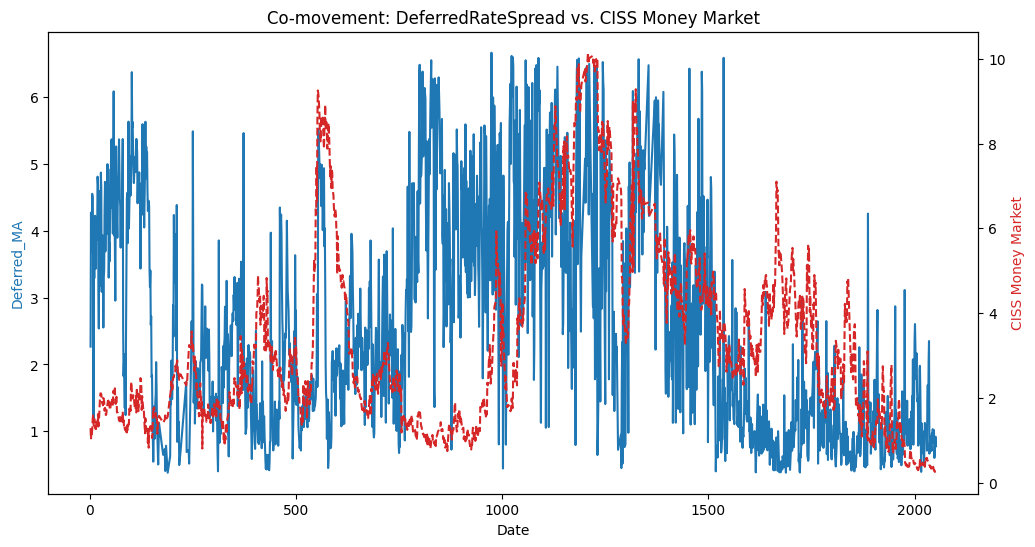

In [134]:
import matplotlib.pyplot as plt

fig, ax1 = plt.subplots(figsize=(12,6))

ax1.set_xlabel('Date')
ax1.set_ylabel('Deferred_MA', color='tab:blue')
ax1.plot(df3.index, df3['DeferredRateSpread'], color='tab:blue', label='Spread')

ax2 = ax1.twinx()
ax2.set_ylabel('CISS Money Market', color='tab:red')
ax2.plot(df3.index, df3['CISS_MM'], color='tab:red', linestyle='--', label='CISS MM')

plt.title('Co-movement: DeferredRateSpread vs. CISS Money Market')
plt.show()

In [123]:
# 1. Feature Engineering on df
df3['Log_DeferredRateSpread'] = np.log1p(df3['DeferredRateSpread'])
df3['Log_BTP_Bund_Spread'] = np.log1p(df3['BTP_Bund_Spread'])
df3['Lagged_Spread'] = df3['DeferredRateSpread'].shift(1)
df3['Lagged_rate'] = df3['DeferredRate'].shift(1)
df3['Delta_Liquidity'] = df3['ExcessLiquidityLn'].diff()
df3['Lag_DFR']= df3['DFR'].shift(192)
df3['Lag_Log_BTP_Bund_Spread']= df3['Log_BTP_Bund_Spread'].shift(96)
df3['Delta_Spread'] = df3['Log_DeferredRateSpread'].diff()
df3['ratio']=df3['Log_BTP_Bund_Spread']/df3['ExcessLiquidityLn']

In [136]:
from sklearn.cluster import KMeans
from sklearn.preprocessing import StandardScaler

# 1. Prepare Data (Handle NaNs)
df_clust = df3[['CISS_MM', 'Deferred_MA']].dropna().copy()

# 2. Standardize (Crucial for K-Means)
scaler = StandardScaler()
df_scaled = scaler.fit_transform(df_clust)

# 3. K-Means for CISS
km_ciss = KMeans(n_clusters=2, random_state=42, n_init=10)
df_clust['Cluster_CISS'] = km_ciss.fit_predict(df_clust[['CISS_MM']])

# 4. K-Means for Repo Spread (Deferred_MA)
km_repo = KMeans(n_clusters=2, random_state=42, n_init=10)
df_clust['Cluster_Repo'] = km_repo.fit_predict(df_clust[['Deferred_MA']])

# 5. Alignment Fix
# K-means labels (0 and 1) are arbitrary. Let's ensure '1' always means 'High Stress'
if df_clust.groupby('Cluster_CISS')['CISS_MM'].mean().idxmin() == 1:
    df_clust['Cluster_CISS'] = 1 - df_clust['Cluster_CISS']
    
if df_clust.groupby('Cluster_Repo')['Deferred_MA'].mean().idxmin() == 1:
    df_clust['Cluster_Repo'] = 1 - df_clust['Cluster_Repo']

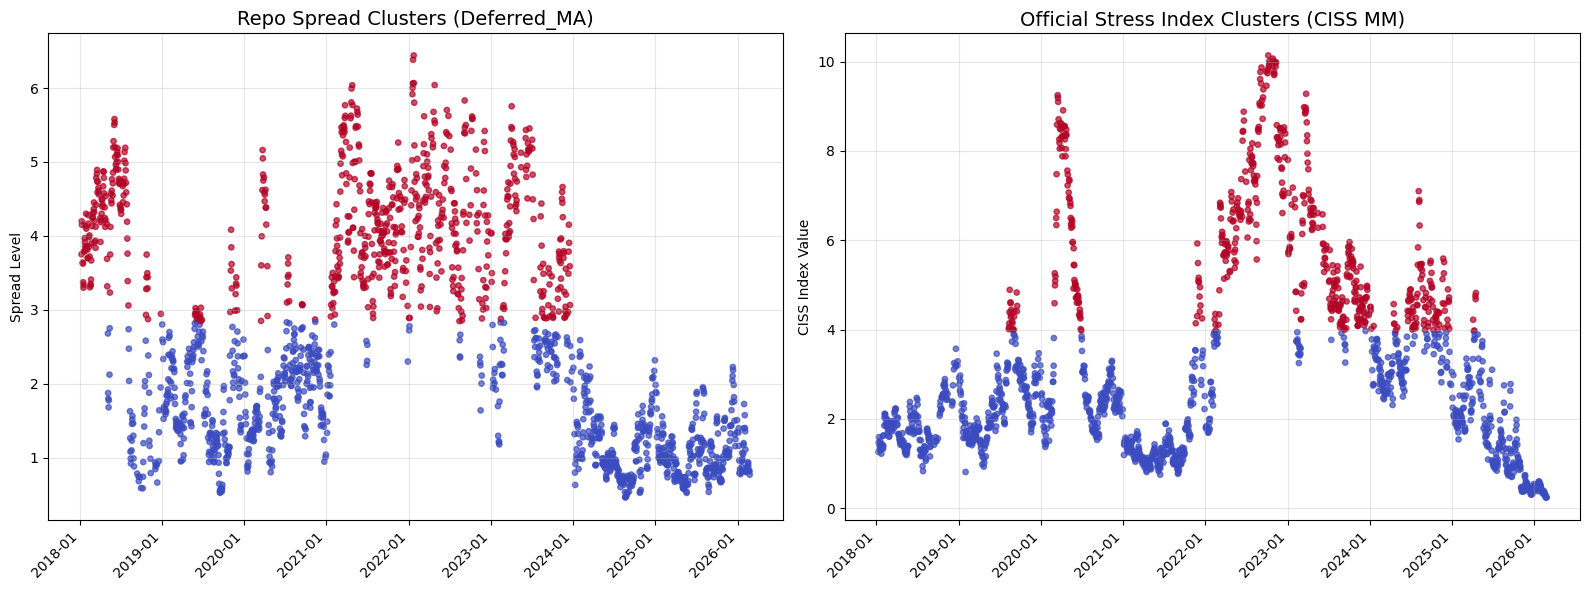

In [137]:
# Assuming df_bQE has a 'Date' column
df_clust['Date'] = df3.loc[df_clust.index, 'Date']
df_clust['Date'] = pd.to_datetime(df_clust['Date'])
import matplotlib.dates as mdates

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(16, 6))

# Subplot 1: Repo Spread Clusters
ax1.scatter(df_clust['Date'], df_clust['Deferred_MA'], 
            c=df_clust['Cluster_Repo'], cmap='coolwarm', s=15, alpha=0.7)
ax1.set_title('Repo Spread Clusters (Deferred_MA)', fontsize=14)
ax1.set_ylabel('Spread Level')

# Subplot 2: CISS MM Clusters
ax2.scatter(df_clust['Date'], df_clust['CISS_MM'], 
            c=df_clust['Cluster_CISS'], cmap='coolwarm', s=15, alpha=0.7)
ax2.set_title('Official Stress Index Clusters (CISS MM)', fontsize=14)
ax2.set_ylabel('CISS Index Value')

# Apply Date Formatting to both axes
for ax in [ax1, ax2]:
    ax.xaxis.set_major_locator(mdates.AutoDateLocator())
    ax.xaxis.set_major_formatter(mdates.DateFormatter('%Y-%m'))
    plt.setp(ax.get_xticklabels(), rotation=45, ha='right')
    ax.grid(alpha=0.3)

plt.tight_layout()
plt.show()

C:\Users\shree\AppData\Local\Programs\Python\Python313\Lib\site-packages\statsmodels\tsa\base\tsa_model.py:473: ValueWarning: An unsupported index was provided. As a result, forecasts cannot be generated. To use the model for forecasting, use one of the supported classes of index.
  self._init_dates(dates, freq)
C:\Users\shree\AppData\Local\Programs\Python\Python313\Lib\site-packages\statsmodels\base\model.py:607: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  warnings.warn("Maximum Likelihood optimization failed to "


                        Markov Switching Model Results                        
Dep. Variable:            Deferred_MA   No. Observations:                 1840
Model:               MarkovRegression   Log Likelihood               -1079.040
Date:                Fri, 10 Apr 2026   AIC                           2190.080
Time:                        08:19:46   BIC                           2278.360
Sample:                             0   HQIC                          2222.631
                               - 1840                                         
Covariance Type:               approx                                         
                             Regime 0 parameters                              
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
const         -9.0530      0.935     -9.679      0.000     -10.886      -7.220
x1             0.5167      0.017     30.107      0.0

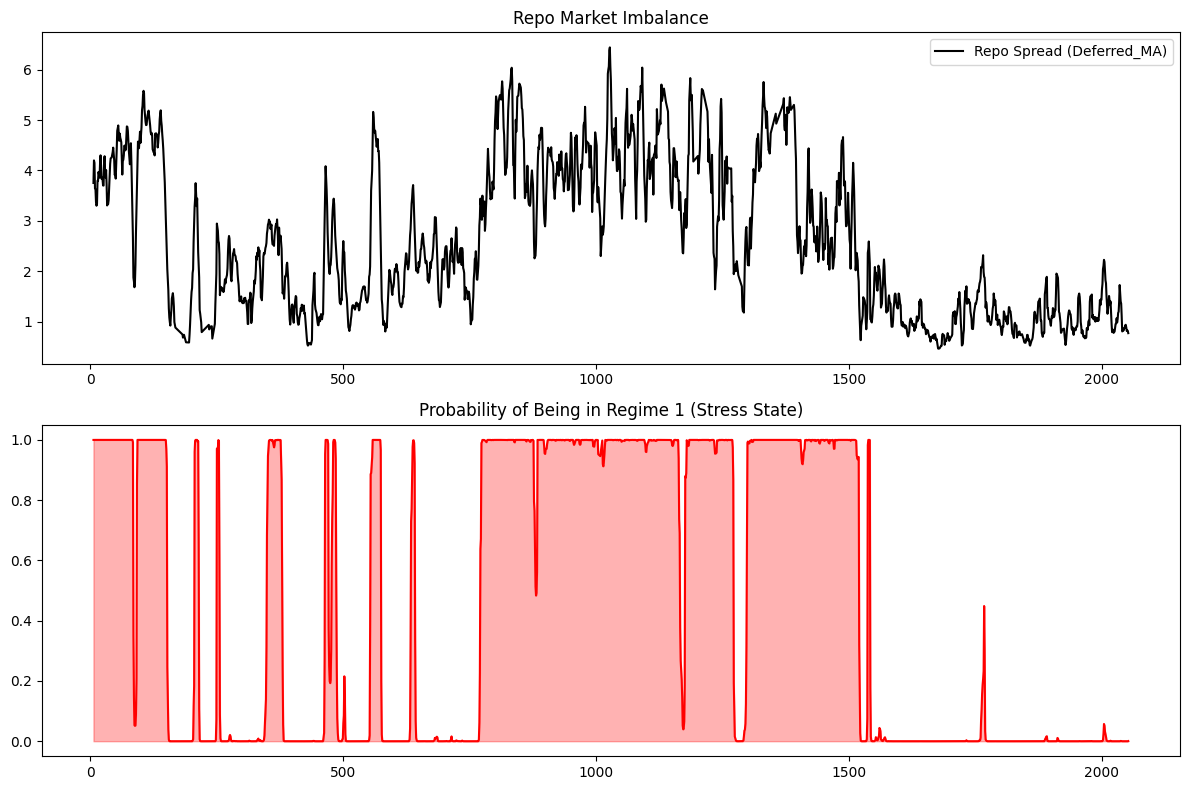

In [126]:
import statsmodels.api as sm

# 1. Prepare the data (Ensure no NaNs and clear variable names)
# We use Deferred_MA as the dependent variable
data_msm = df3[['Deferred_MA', 'Lagged_Spread', 'Log_BTP_Bund_Spread', 
                   'Delta_Liquidity', 'ExcessLiquidityLn', 'DFR']].dropna()

# 2. Define the Dependent and Independent variables
y = data_msm['Deferred_MA']
X = data_msm[['Lagged_Spread', 'Log_BTP_Bund_Spread', 'Delta_Liquidity', 
              'ExcessLiquidityLn', 'DFR']]

# 3. Fit the Markov Switching Model
# k_regimes=2: One for "Normal", one for "Stress"
# switching_variance=True: Crisis periods usually have higher volatility
model_msm = sm.tsa.MarkovRegression(y, k_regimes=2, exog=X, switching_variance=True)
res_msm = model_msm.fit()

print(res_msm.summary())

# 4. Plot the "Smoothed Probabilities" of being in Regime 1 (Crisis State)
fig, axes = plt.subplots(2, 1, figsize=(12, 8))

axes[0].plot(data_msm.index, y, label='Repo Spread (Deferred_MA)', color='black')
axes[0].set_title('Repo Market Imbalance')
axes[0].legend()

axes[1].plot(data_msm.index, res_msm.smoothed_marginal_probabilities[1], color='red')
axes[1].set_title('Probability of Being in Regime 1 (Stress State)')
axes[1].fill_between(data_msm.index, 0, res_msm.smoothed_marginal_probabilities[1], color='red', alpha=0.3)

plt.tight_layout()
plt.show()